In [1]:
import pandas as pd

df = pd.read_excel("/kaggle/input/ticksdataset/Tick-cdc-report 2008-2025.csv")
print(df.columns)

Index(['USI', 'Collection Date', 'Year', 'County', 'Municipality', 'Latitude',
       'Longitude', 'CollectionMethod', 'Species', 'Nymph', 'Adult Male',
       'Adult Female', 'No Tested', 'No Positive', 'B_Burg', 'A_Phag',
       'Ba_Micro', 'BOR_MIYA', 'Larvae', 'Distance (m)', 'Temprature'],
      dtype='object')


In [2]:
df["Collection Date"] = pd.to_datetime(df["Collection Date"])

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import folium
from folium.plugins import MarkerCluster

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 140

df = pd.read_excel("/kaggle/input/ticksdataset/Tick-cdc-report 2008-2025.csv")

# Standardize column names (so we can code cleanly)
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
)

# Parse date if present
df["collection_date"] = pd.to_datetime(df["collection_date"], errors="coerce")

# Ensure numeric columns are numeric
num_cols = ["latitude","longitude","nymph","larvae","adult_male","adult_female",
            "no_tested","no_positive","distance_m","temprature",
            "b_burg","a_phag","ba_micro","bor_miya"]
for c in num_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Derived columns
df["no_negative"] = df["no_tested"] - df["no_positive"]
df["positivity_rate"] = np.where(df["no_tested"] > 0, df["no_positive"] / df["no_tested"], np.nan)

df.head()

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pan

,usi,collection_date,year,county,municipality,latitude,longitude,collectionmethod,species,nymph,...,no_positive,b_burg,a_phag,ba_micro,bor_miya,larvae,distance_m,temprature,no_negative,positivity_rate
0,5201800607,2018-11-08,2018,Fayette,Connellsville City,40.02045,-79.60083,Dragging,Dermacentor variabilis,0,...,0,0,0,0,0,0,749.0,42.0,0,NaN
1,5201800042,2018-11-06,2018,Cambria,Vintondale Boro,40.48088,-78.92003,Dragging,Ixodes scapularis,0,...,1,1,0,0,0,0,100.0,59.0,2,0.333333
2,5201800010,2018-10-30,2018,Schuylkill,Pine Grove Twp,40.52689,-76.47026,Dragging,Ixodes scapularis,0,...,1,1,0,0,0,0,300.0,52.0,0,1.000000
3,5201800060,2018-11-09,2018,Lebanon,East Hanover Twp,40.42231,-76.60083,Dragging,Ixodes scapularis,0,...,4,4,0,0,0,0,510.0,42.0,6,0.400000
4,5201800404,2018-11-01,2018,Carbon,Penn Forest Twp,40.93271,-75.65673,Dragging,Ixodes scapularis,0,...,5,5,0,0,0,0,612.0,60.0,5,0.500000


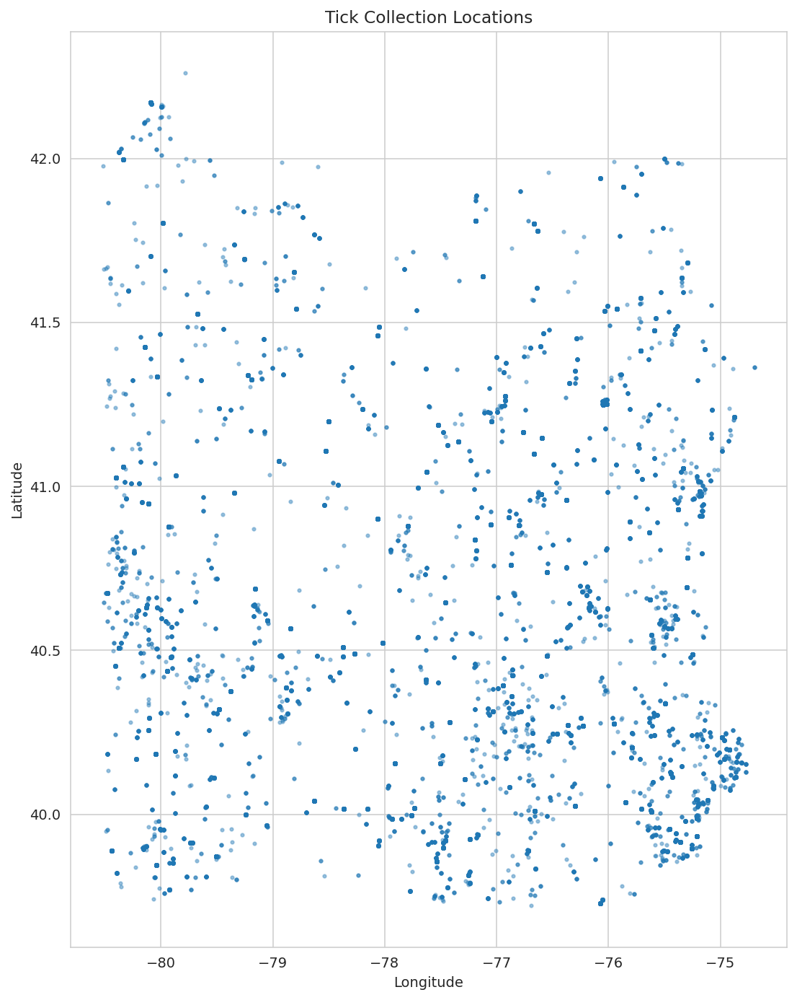

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,10))
plt.scatter(
    df["longitude"],
    df["latitude"],
    s=5,
    alpha=0.4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Tick Collection Locations")
plt.tight_layout()
plt.savefig("map_tick_locations_static.png")
plt.show()

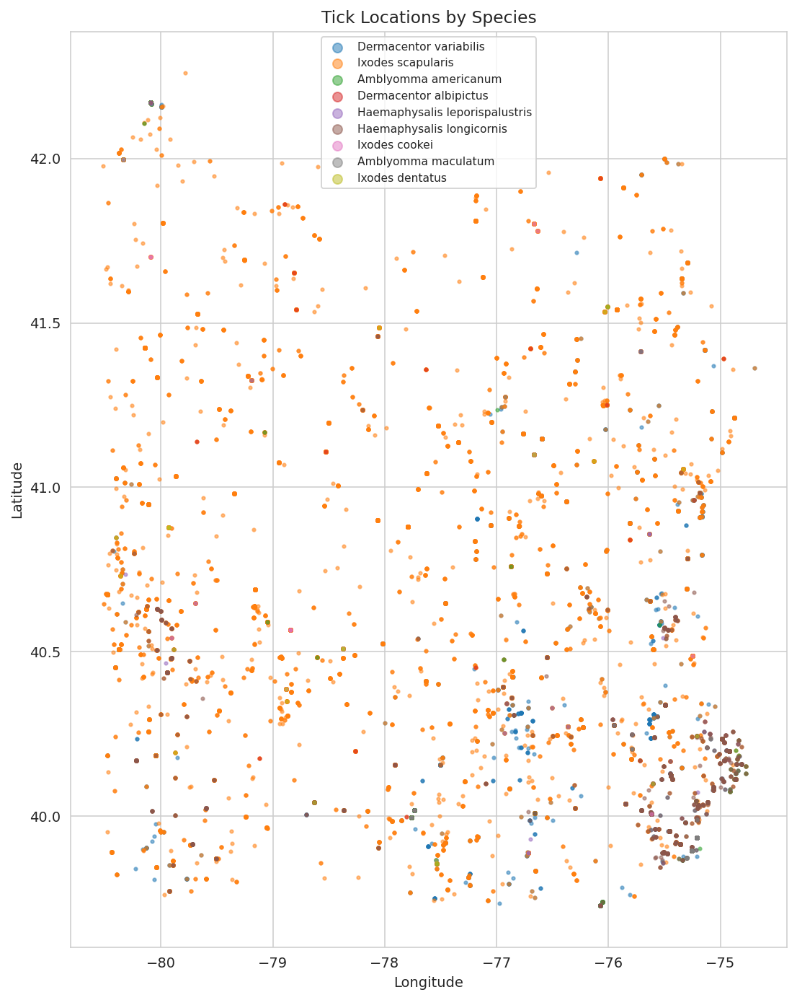

In [5]:
plt.figure(figsize=(8,10))
for sp in df["species"].dropna().unique():
    sub = df[df["species"] == sp]
    plt.scatter(
        sub["longitude"],
        sub["latitude"],
        s=5,
        alpha=0.5,
        label=sp
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Tick Locations by Species")
plt.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.savefig("map_tick_locations_by_species.png")
plt.show()


In [6]:
!pip install contextily geopandas pyproj

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.9/35.9 MB 47.6 MB/s eta 0:00:00


In [7]:
import geopandas as gpd
from shapely.geometry import Point

# Create geometry
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.longitude, df.latitude),
    crs="EPSG:4326"  # lat/lon
)

# Reproject to Web Mercator (required for basemaps)
gdf = gdf.to_crs(epsg=3857)


In [8]:
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt

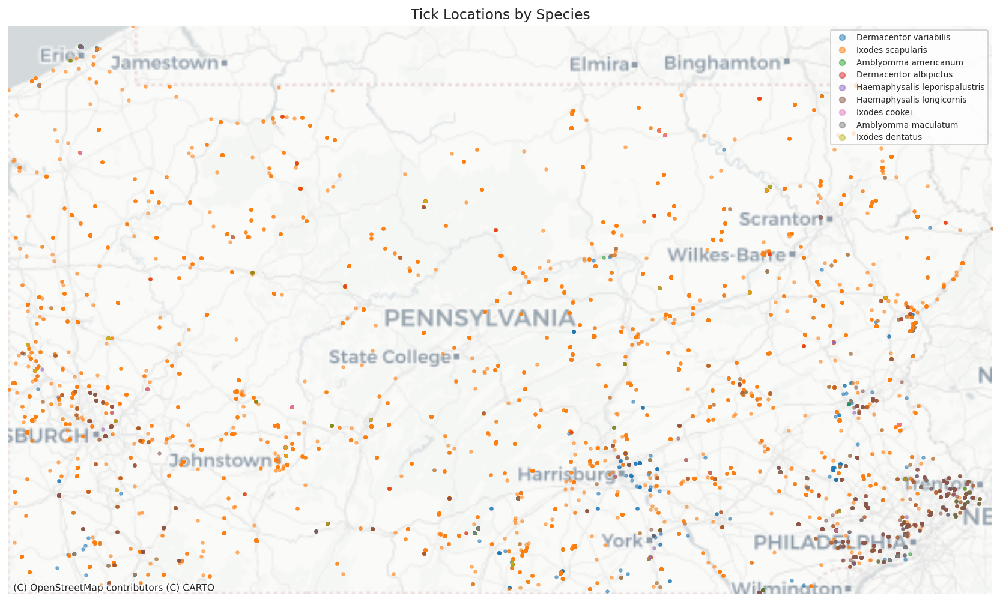

In [9]:
fig, ax = plt.subplots(figsize=(12,8))  # wider aspect

for sp in gdf["species"].dropna().unique():
    sub = gdf[gdf["species"] == sp]
    ax.scatter(
        sub.geometry.x,
        sub.geometry.y,
        s=6,
        alpha=0.5,
        label=sp
    )

# ---- FIXES ----
xmin, ymin, xmax, ymax = gdf.total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
# ----------------

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Tick Locations by Species")
ax.set_axis_off()
ax.legend(markerscale=2, fontsize=7)

plt.tight_layout()
plt.savefig("map_all_species_basemap_fixed.png", dpi=300)
plt.show()

In [10]:
ax.set_aspect("equal")

In [11]:
xmin, ymin, xmax, ymax = gdf.total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

(4825621.592091625, 5200012.1176382825)

In [12]:
def fix_axes(ax, gdf):
    xmin, ymin, xmax, ymax = gdf.total_bounds
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_axis_off()

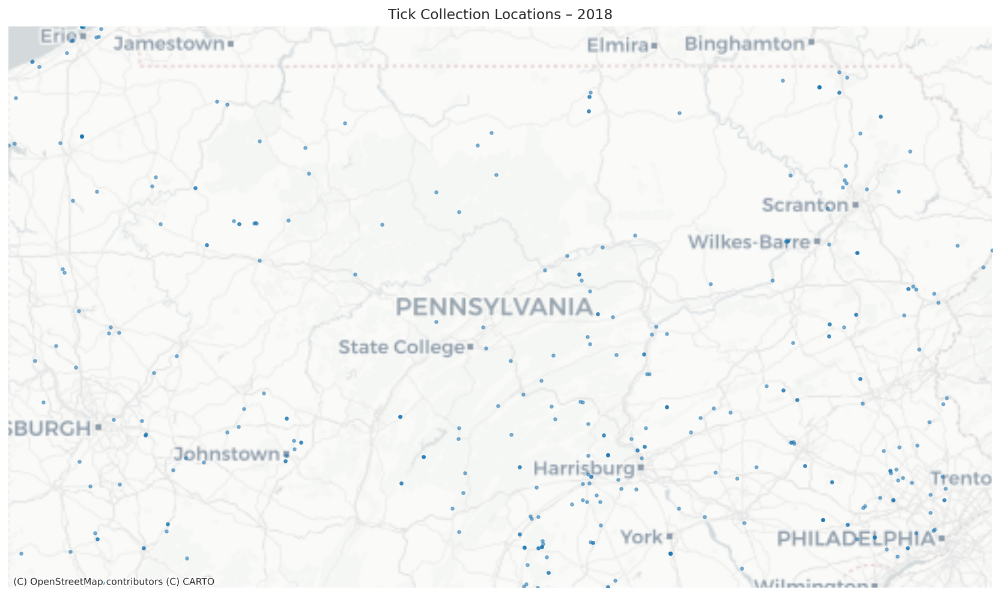

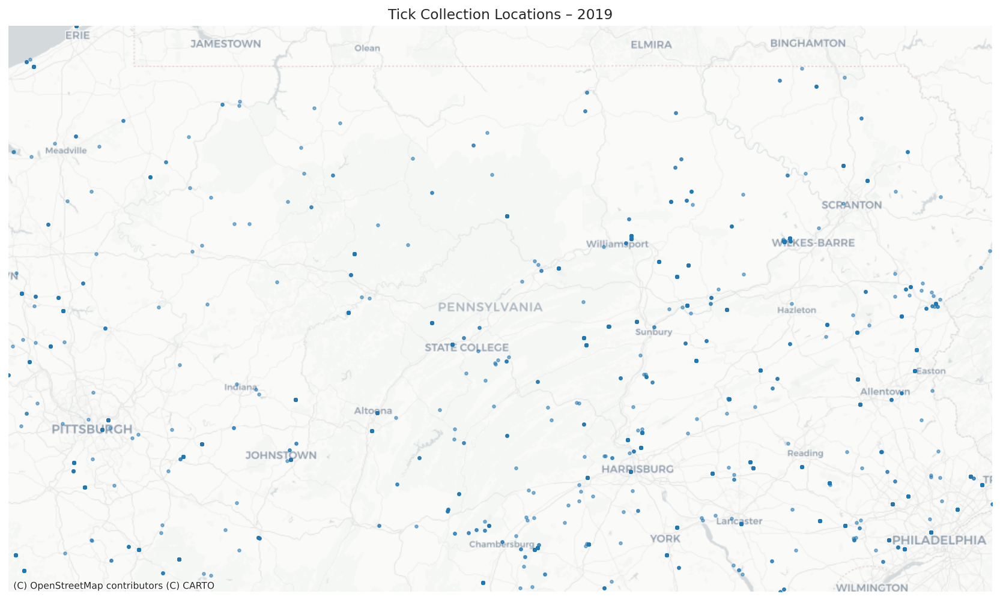

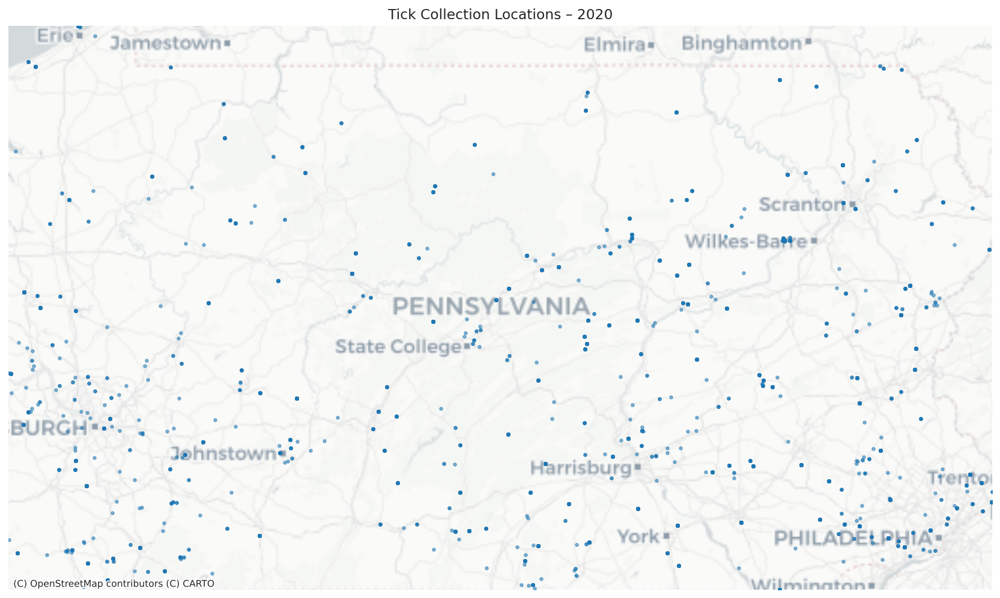

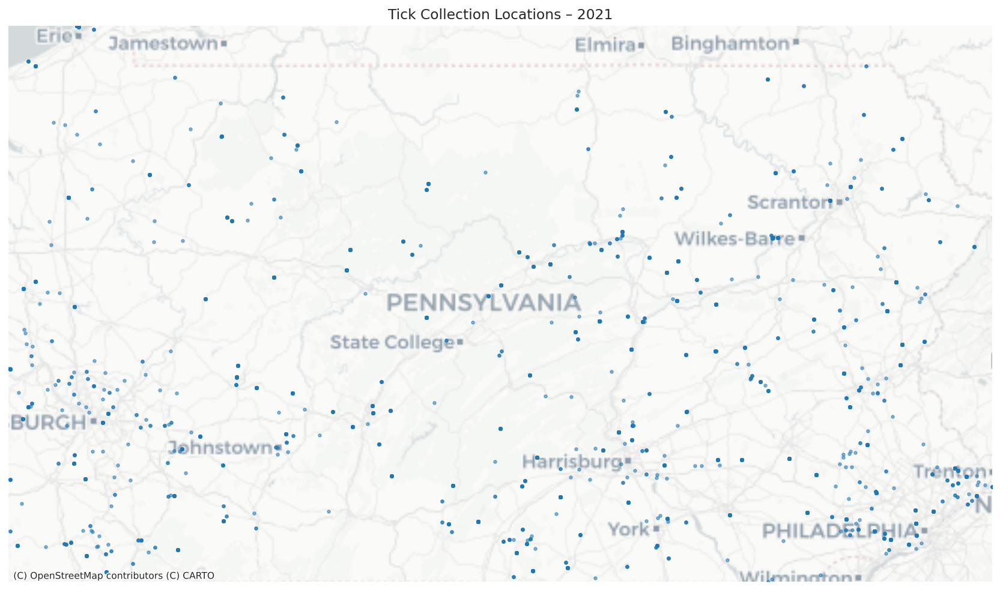

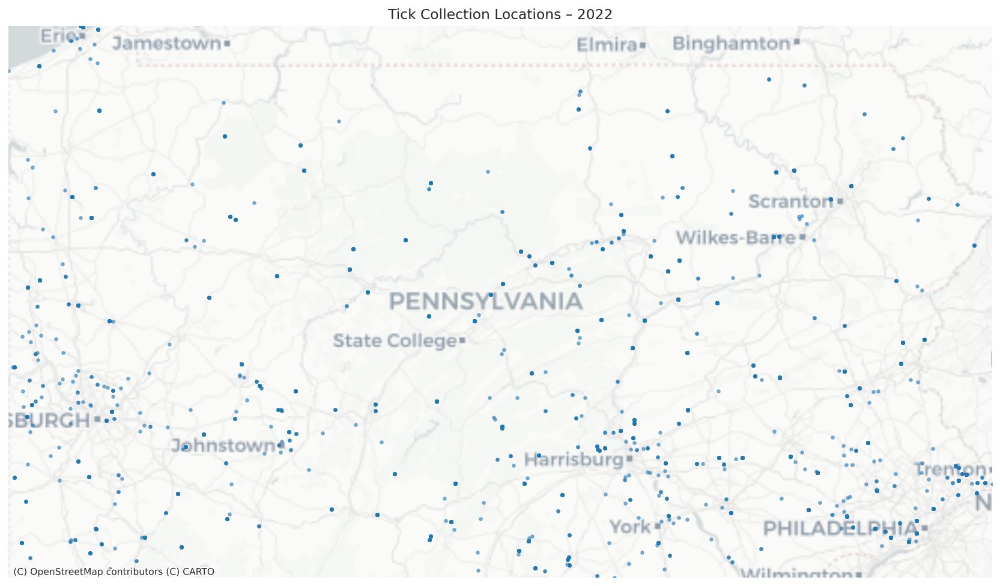

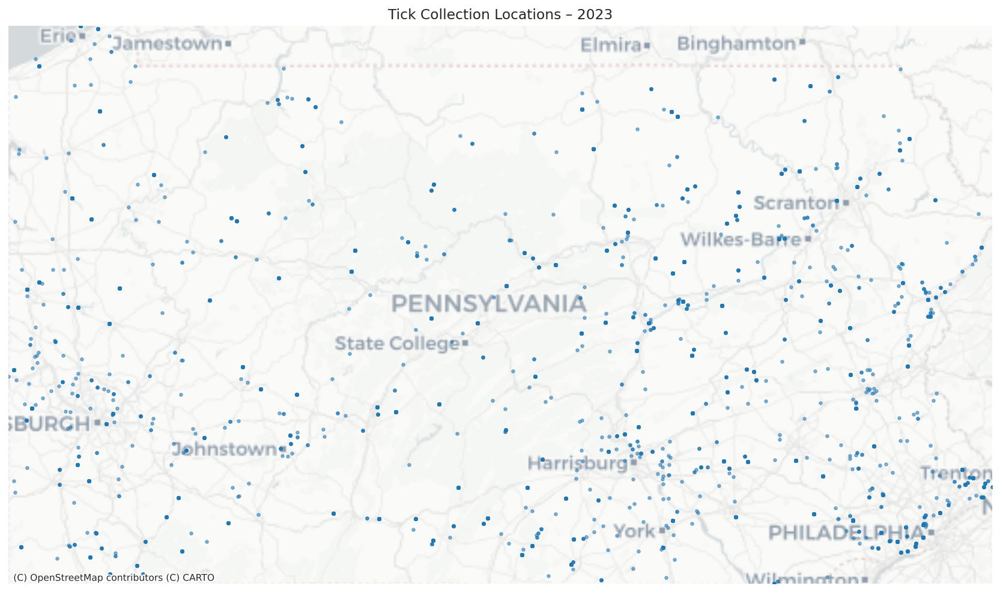

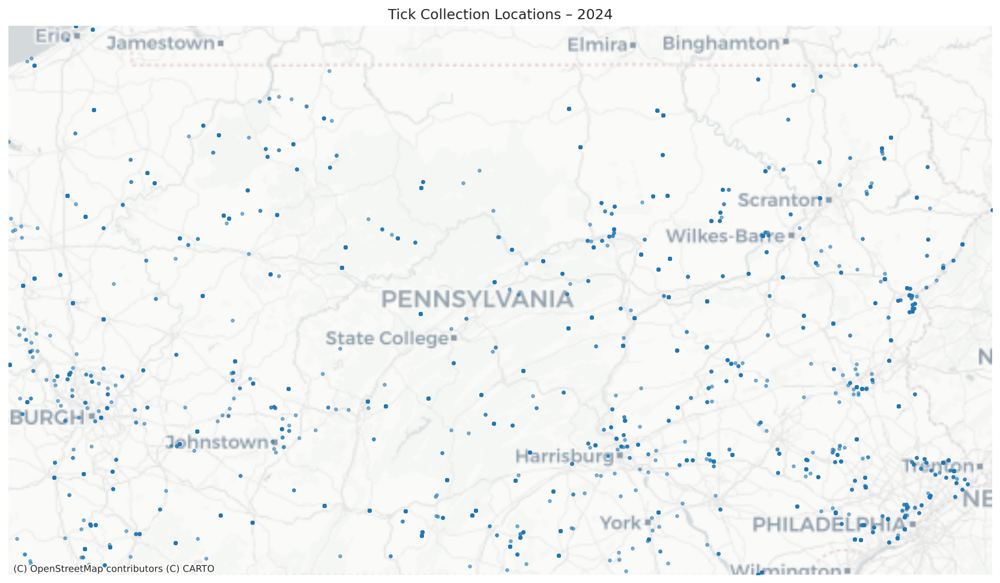

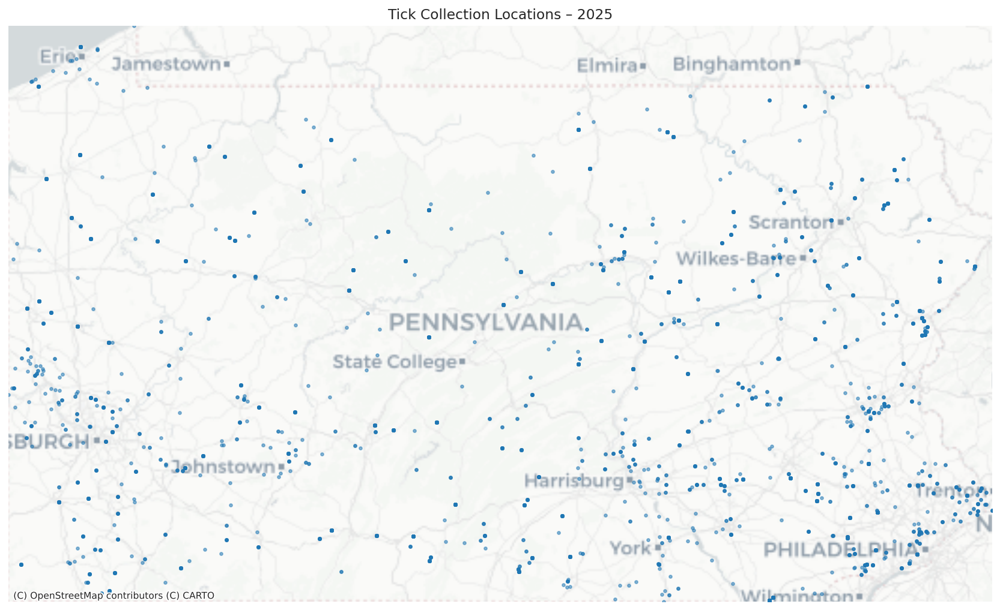

In [13]:
years = sorted(gdf["year"].dropna().unique())

for y in years:
    sub = gdf[gdf["year"] == y]
    if len(sub) == 0:
        continue

    fig, ax = plt.subplots(figsize=(12,8))

    ax.scatter(
        sub.geometry.x,
        sub.geometry.y,
        s=6,
        alpha=0.5
    )

    fix_axes(ax, sub)
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

    ax.set_title(f"Tick Collection Locations – {int(y)}")

    plt.tight_layout()
    plt.savefig(f"map_all_species_{int(y)}.png", dpi=300)
    plt.show()
    plt.close()

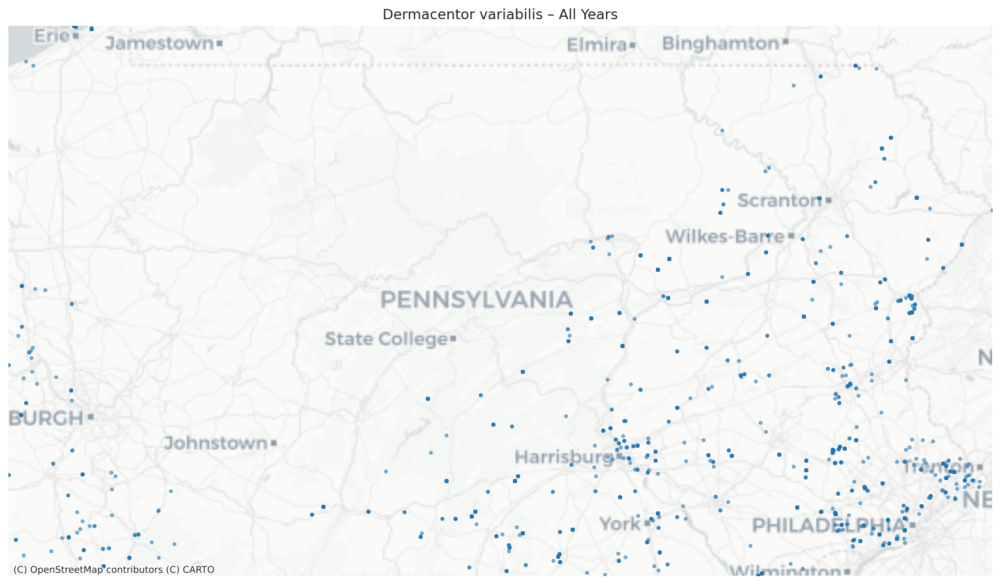

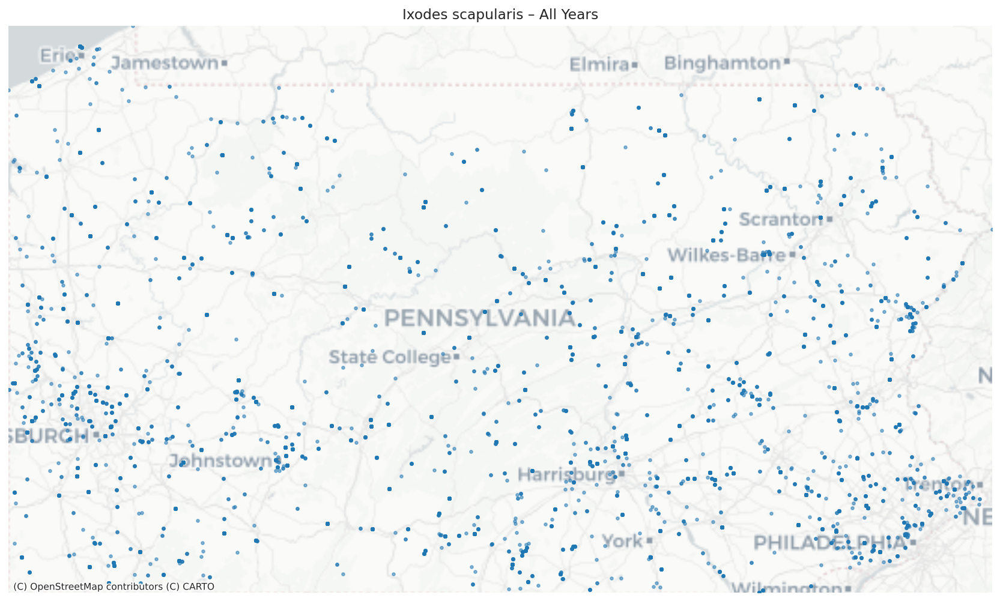

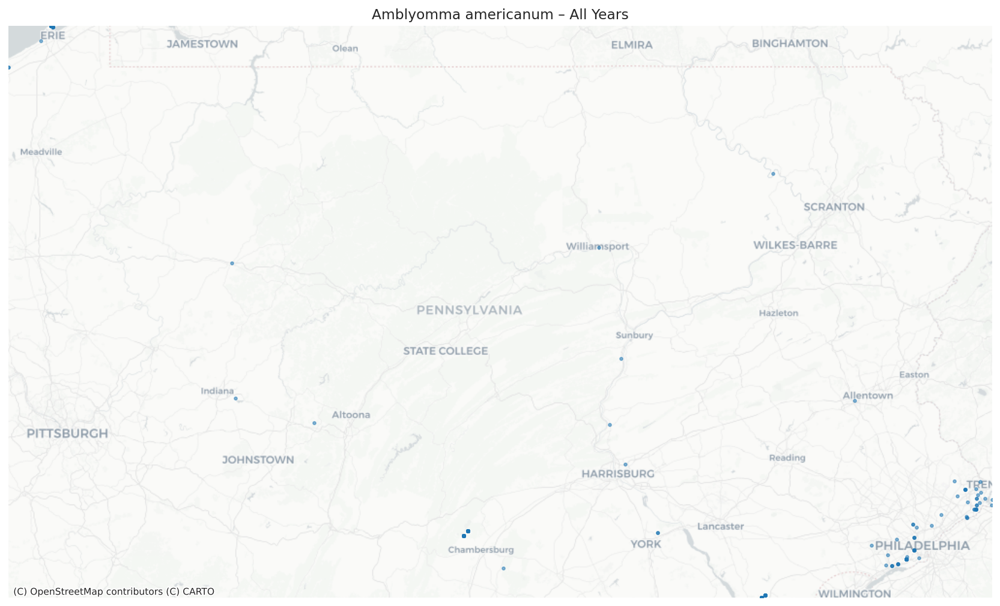

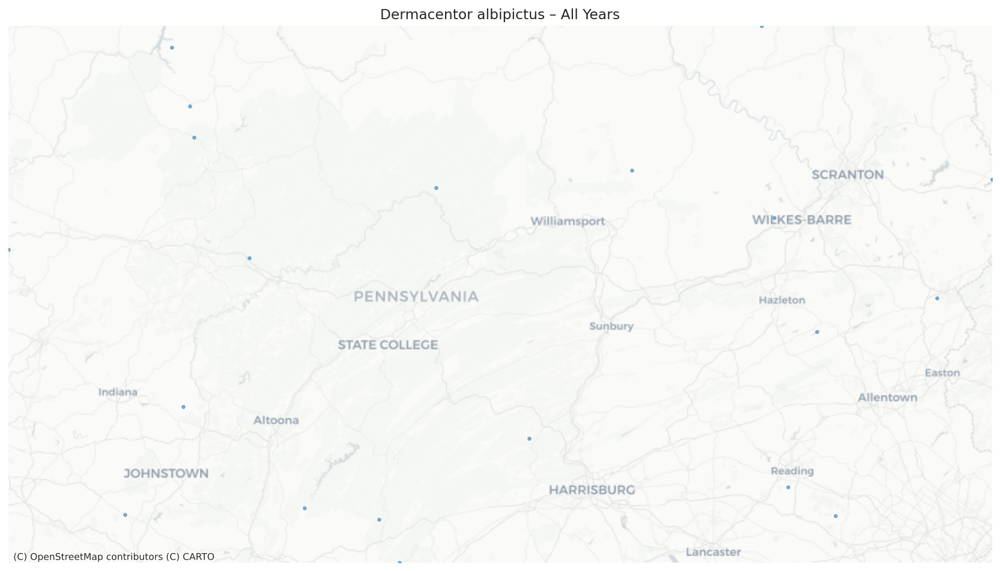

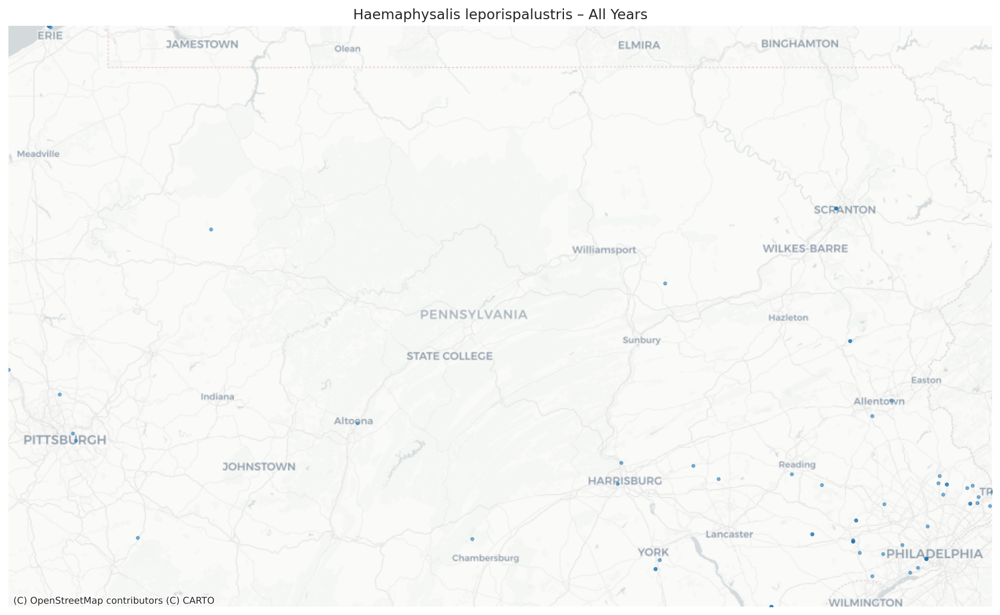

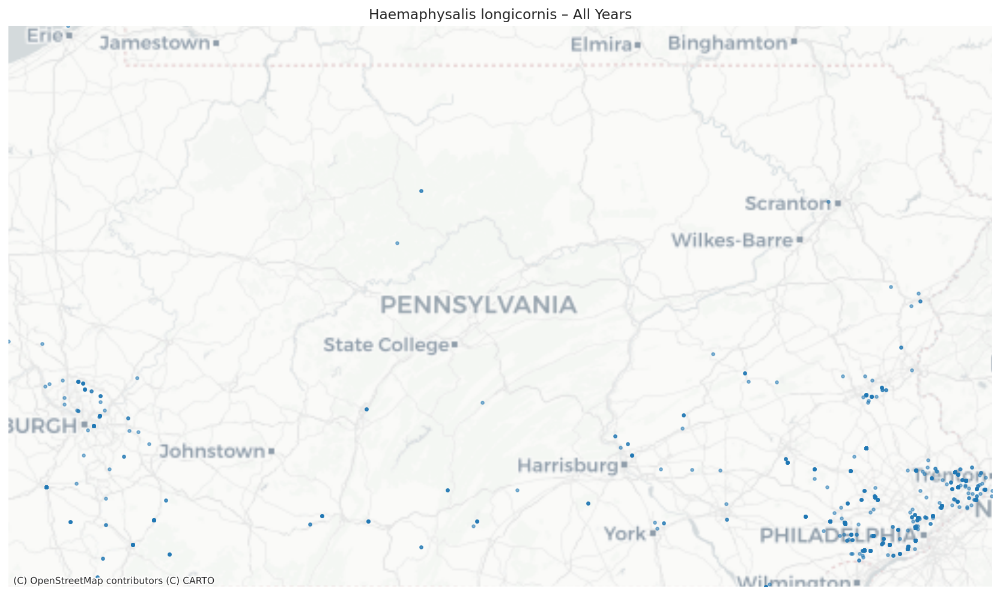

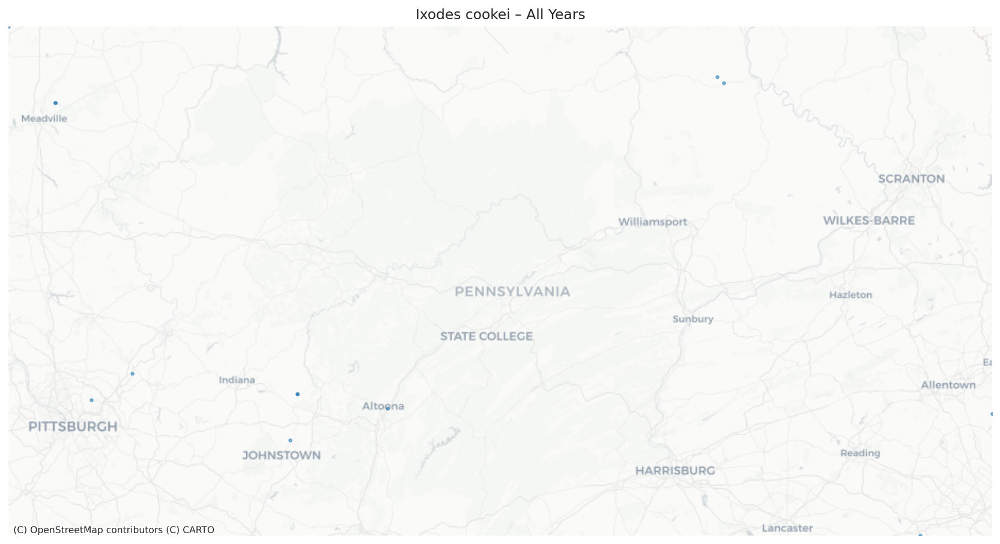

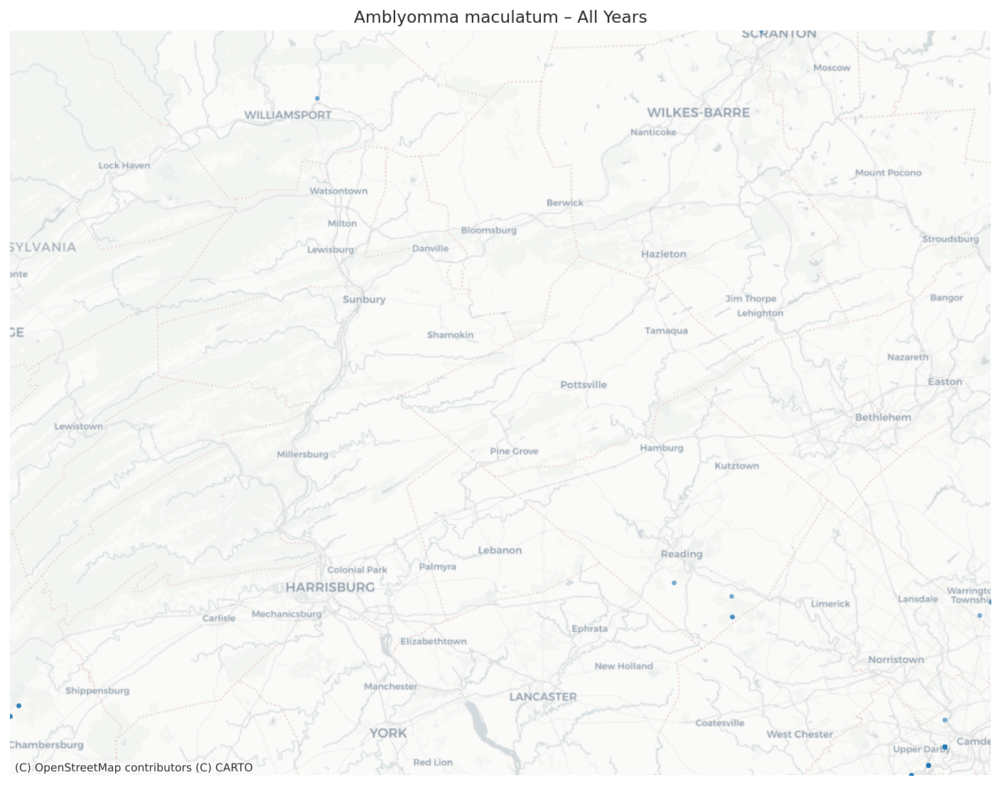

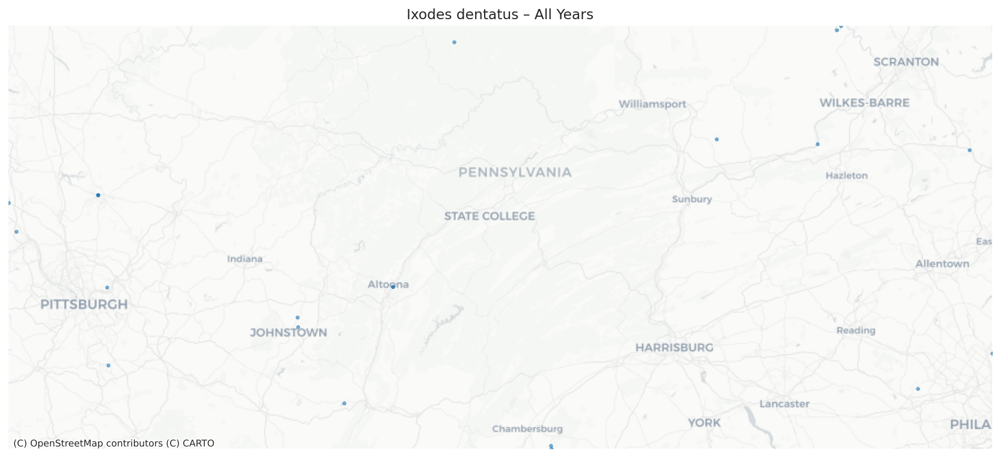

In [14]:
species_list = gdf["species"].dropna().unique()

for sp in species_list:
    sub = gdf[gdf["species"] == sp]
    if len(sub) == 0:
        continue

    fig, ax = plt.subplots(figsize=(12,8))

    ax.scatter(
        sub.geometry.x,
        sub.geometry.y,
        s=6,
        alpha=0.5
    )

    fix_axes(ax, sub)
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

    ax.set_title(f"{sp} – All Years")

    plt.tight_layout()
    plt.savefig(f"map_{sp.replace(' ','_')}_all_years.png", dpi=300)
    plt.show()
    plt.close()

In [15]:
for sp in species_list:
    for y in years:
        sub = gdf[(gdf["species"] == sp) & (gdf["year"] == y)]
        if len(sub) == 0:
            continue

        fig, ax = plt.subplots(figsize=(12,8))

        ax.scatter(
            sub.geometry.x,
            sub.geometry.y,
            s=8,
            alpha=0.6
        )

        fix_axes(ax, sub)
        ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

        ax.set_title(f"{sp} – {int(y)}")

        plt.tight_layout()
        fname = f"map_{sp.replace(' ','_')}_{int(y)}.png"
        plt.savefig(fname, dpi=300)
        plt.close()

/tmp/ipykernel_13/740173654.py:3: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(xmin, xmax)
/tmp/ipykernel_13/740173654.py:4: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(ymin, ymax)
/tmp/ipykernel_13/740173654.py:3: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(xmin, xmax)
/tmp/ipykernel_13/740173654.py:4: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(ymin, ymax)
/tmp/ipykernel_13/740173654.py:3: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(xmin, xmax)
/tmp/ipykernel_13/740173654.py:4: UserWarning: Attempting to set identical low and high ylims makes transformation singu

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# 2) Time series: No Tested & No Positive
ts = (df
      .groupby("Collection Date")[["No Tested", "No Positive"]]
      .sum()
      .reset_index())

plt.figure(figsize=(10, 4))
sns.lineplot(data=ts, x="Collection Date", y="No Tested", label="No Tested")
sns.lineplot(data=ts, x="Collection Date", y="No Positive", label="No Positive")
plt.title("Ticks Tested and Positive Over Time")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 3) Bar: total ticks by life stage
stage_df = pd.DataFrame({
    "LifeStage": ["Nymph", "Adult Male", "Adult Female", "Larvae"],
    "Count": [
        df["Nymph"].sum(),
        df["Adult Male"].sum(),
        df["Adult Female"].sum(),
        df["Larvae"].sum()
    ]
})

plt.figure(figsize=(6, 4))
sns.barplot(data=stage_df, x="LifeStage", y="Count")
plt.title("Total Ticks by Life Stage")
plt.tight_layout()
plt.show()

# 4) Scatter: temperature vs positives
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Temprature",
    y="No Positive",
    hue="Species",
    alpha=0.7
)
plt.title("Positive Ticks vs Temperature")
plt.tight_layout()
plt.show()


KeyError: 'Collection Date'

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Year")
plt.title("Number of Tick Submissions per Year")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import folium
from folium.plugins import MarkerCluster

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 140

df = pd.read_excel("/kaggle/input/ticksdataset/Tick-cdc-report 2008-2025.csv")

# Standardize column names (so we can code cleanly)
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
)

# Parse date if present
df["collection_date"] = pd.to_datetime(df["collection_date"], errors="coerce")

# Ensure numeric columns are numeric
num_cols = ["latitude","longitude","nymph","larvae","adult_male","adult_female",
            "no_tested","no_positive","distance_m","temprature",
            "b_burg","a_phag","ba_micro","bor_miya"]
for c in num_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Derived columns
df["no_negative"] = df["no_tested"] - df["no_positive"]
df["positivity_rate"] = np.where(df["no_tested"] > 0, df["no_positive"] / df["no_tested"], np.nan)

df.head()

In [ ]:
stage = (df.groupby("species")[["adult_male","adult_female","nymph","larvae"]]
         .sum()
         .sort_values("nymph", ascending=False))

ax = stage.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Life Stage Counts by Species")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("01_life_stages_by_species.png")
plt.show()

In [ ]:
tests = (df.groupby("species")[["no_tested","no_positive","no_negative"]]
         .sum()
         .sort_values("no_tested", ascending=False))

ax = tests[["no_positive","no_negative"]].plot(kind="bar", figsize=(12,6))
plt.title("Positive vs Negative Tests by Species")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("02_pos_neg_by_species.png")
plt.show()

In [ ]:
for sp in species_list:
    d = df[df["species"] == sp]
    if len(d) < 10:
        continue

    plt.figure(figsize=(7,9))
    plt.hexbin(
        d["longitude"],
        d["latitude"],
        gridsize=45,
        cmap="inferno",
        mincnt=1
    )

    plt.colorbar(label="Tick Density")
    plt.title(f"{sp} – Spatial Density")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.tight_layout()
    plt.savefig(f"{sp}_spatial_density.png", dpi=300)
    plt.show()

In [ ]:
path_cols = ["b_burg","a_phag","ba_micro","bor_miya"]
path_totals = df[path_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(9,5))
sns.barplot(x=path_totals.values, y=path_totals.index)
plt.title("Total Pathogen Detections")
plt.xlabel("Count")
plt.ylabel("Pathogen")
plt.tight_layout()
plt.savefig("04_pathogen_totals.png")
plt.show()

In [ ]:
species_path = df.groupby("species")[path_cols].sum()

plt.figure(figsize=(10,6))
sns.heatmap(species_path, annot=False, cmap="Reds", linewidths=0.5)
plt.title("Species vs Pathogen (Sum)")
plt.tight_layout()
plt.savefig("05_species_pathogen_heatmap.png")
plt.show()

In [ ]:
yearly = df.groupby("year")[["no_tested","no_positive"]].sum().sort_index()

plt.figure(figsize=(10,5))
plt.plot(yearly.index, yearly["no_tested"], marker="o", label="No Tested")
plt.plot(yearly.index, yearly["no_positive"], marker="o", label="No Positive")
plt.title("Yearly Testing Trend")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.savefig("06_yearly_test_positive_trend.png")
plt.show()

In [ ]:
yearly_path = df.groupby("year")[path_cols].sum().sort_index()

for c in path_cols:
    plt.figure(figsize=(10,4))
    plt.plot(yearly_path.index, yearly_path[c], marker="o")
    plt.title(f"Yearly Trend: {c.upper()}")
    plt.xlabel("Year")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.savefig(f"07_yearly_{c}.png")
    plt.show()

In [ ]:
for sp in species_list:
    d = df[df["species"] == sp]

    yearly = d.groupby("year")[["no_tested", "no_positive"]].sum()
    yearly["positivity_rate"] = yearly["no_positive"] / yearly["no_tested"]

    plt.figure(figsize=(8,4))
    plt.plot(yearly.index, yearly["positivity_rate"], marker="o")

    plt.title(f"{sp} – Positivity Rate Over Time")
    plt.xlabel("Year")
    plt.ylabel("Positivity Rate")
    plt.tight_layout()
    plt.savefig(f"{sp}_positivity_rate_over_time.png", dpi=300)
    plt.show()

In [ ]:
county = df.groupby("county")[["no_tested","no_positive"]].sum()
county["positivity_rate_%"] = np.where(county["no_tested"]>0, county["no_positive"]/county["no_tested"]*100, np.nan)
county = county.sort_values("no_tested", ascending=False).head(25)

plt.figure(figsize=(10,7))
sns.barplot(x=county["no_tested"].values, y=county.index)
plt.title("Top 25 Counties by Total Tested")
plt.xlabel("No Tested")
plt.tight_layout()
plt.savefig("11_top_counties_tested.png")
plt.show()

county2 = county.sort_values("positivity_rate_%", ascending=False)

plt.figure(figsize=(10,7))
sns.barplot(x=county2["positivity_rate_%"].values, y=county2.index)
plt.title("Top 25 Counties: Positivity Rate (%)")
plt.xlabel("Positivity Rate (%)")
plt.tight_layout()
plt.savefig("12_top_counties_positivity_rate.png")
plt.show()

In [ ]:
plt.figure(figsize=(8,4))
sns.histplot(df["distance_m"].dropna(), bins=30, kde=True)
plt.title("Distance (m) Distribution")
plt.xlabel("Distance (m)")
plt.tight_layout()
plt.savefig("13_distance_distribution.png")
plt.show()

plt.figure(figsize=(9,6))
sns.scatterplot(data=df, x="distance_m", y="positivity_rate", alpha=0.6)
plt.title("Distance (m) vs Positivity Rate")
plt.tight_layout()
plt.savefig("14_distance_vs_positivity.png")
plt.show()